# Exploratory Data Analysis and Feature Engineering

This notebook is used for exploratory data analysis (EDA) and evaluation of candidate features.

The `eda` dataframe is an intermediate dataset that combines raw variables and derived features for exploratory purposes. Not every feature created here will be included in the final model.

Final feature selection, preprocessing, and model training should be performed separately using only information available at prediction time and without target leakage.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import src.transactions_train
import src.logs_train
import importlib

In [3]:
BASE_DIR = Path("..")
DATA_RAW = BASE_DIR / "data" / "raw"
DATA_INTERIM = BASE_DIR / "data" / "interim"

### 1. Data loading and inital inspection

In [4]:
train = pd.read_csv(DATA_RAW / "train.csv")

### 2. Target Variable: Churn

Examine the target distribution and check for class imbalance.

In [68]:
class_distribution = (
    train["is_churn"]
    .value_counts()
    .rename(index={0: "Stayed", 1: "Churned"})
    .to_frame("Count")
)

class_distribution["Percentage"] = (
    class_distribution["Count"] / len(train) * 100
)

class_distribution

,Count,Percentage
is_churn,,
Stayed,929460,93.607713
Churned,63471,6.392287


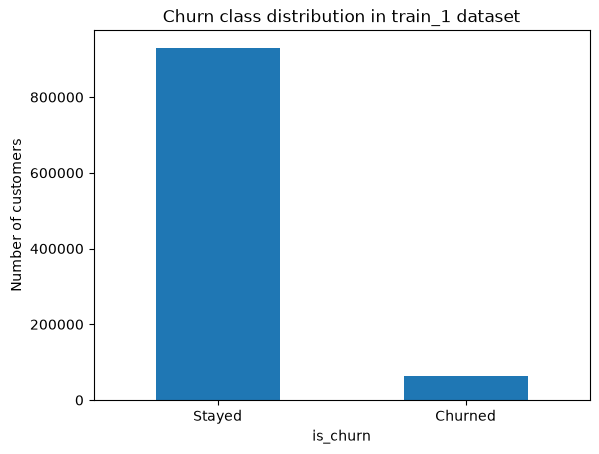

In [69]:
class_distribution["Count"].plot(kind="bar")
plt.xticks(rotation=0)
plt.ylabel("Number of customers")
plt.title("Churn class distribution in train_1 dataset")
plt.show()

### 3. User Profile Features

Explore whether user profile characteristics are associated with different churn rates.

In [6]:
members = pd.read_csv(DATA_RAW / "members_v3.csv")

In [7]:
eda=train.merge(members, on="msno", how="left")  
eda.head()

,msno,is_churn,city,bd,gender,registered_via,registration_init_time
0,waLDQMmcOu2jLDaV1ddDkgCrB/jl6sD66Xzs0Vqax1Y=,1,18.0,36.0,female,9.0,20050406.0
1,QA7uiXy8vIbUSPOkCf9RwQ3FsT8jVq2OxDr8zqa7bRQ=,1,10.0,38.0,male,9.0,20050407.0
2,fGwBva6hikQmTJzrbz/2Ezjm5Cth5jZUNvXigKK2AFA=,1,11.0,27.0,female,9.0,20051016.0
3,mT5V8rEpa+8wuqi6x0DoVd3H5icMKkE9Prt49UlmK+4=,1,13.0,23.0,female,9.0,20051102.0
4,XaPhtGLk/5UvvOYHcONTwsnH97P4eGECeq+BARGItRw=,1,3.0,27.0,male,9.0,20051228.0


In [72]:
eda.isna().sum()

msno                           0
is_churn                       0
city                      115770
bd                        115770
gender                    601239
registered_via            115770
registration_init_time    115770
dtype: int64

#### 3.1. City

In [73]:
city_churn = (
    eda.groupby("city")["is_churn"]
    .agg(
        users="size",
        churned="sum",
        churn_rate="mean"
    )
)

city_churn = city_churn[
    city_churn["users"] >= 100
].sort_values(
    "churn_rate",
    ascending=False
)

city_churn

,users,churned,churn_rate
city,,,
21.0,5286,533,0.100832
12.0,11554,1123,0.097196
8.0,7690,744,0.096749
10.0,6533,595,0.091076
4.0,47945,4264,0.088935
5.0,71299,6248,0.087631
6.0,26022,2239,0.086043
22.0,42129,3549,0.084241
15.0,43356,3652,0.084233


#### 3.2. Gender

In [74]:
eda["gender_eda"] = eda["gender"].fillna("Unknown")
eda.head()

,msno,is_churn,city,bd,gender,registered_via,registration_init_time,gender_eda
0,waLDQMmcOu2jLDaV1ddDkgCrB/jl6sD66Xzs0Vqax1Y=,1,18.0,36.0,female,9.0,20050406.0,female
1,QA7uiXy8vIbUSPOkCf9RwQ3FsT8jVq2OxDr8zqa7bRQ=,1,10.0,38.0,male,9.0,20050407.0,male
2,fGwBva6hikQmTJzrbz/2Ezjm5Cth5jZUNvXigKK2AFA=,1,11.0,27.0,female,9.0,20051016.0,female
3,mT5V8rEpa+8wuqi6x0DoVd3H5icMKkE9Prt49UlmK+4=,1,13.0,23.0,female,9.0,20051102.0,female
4,XaPhtGLk/5UvvOYHcONTwsnH97P4eGECeq+BARGItRw=,1,3.0,27.0,male,9.0,20051228.0,male


In [75]:
eda["gender_eda"].value_counts(normalize=True)*100

gender_eda
Unknown    60.551942
male       20.775260
female     18.672798
Name: proportion, dtype: float64

In [76]:
gender_churn = (
    eda.groupby("gender_eda")["is_churn"]
    .agg(["count", "mean"])
)
gender_churn["churn_rate"] = gender_churn["mean"] * 100

gender_churn

,count,mean,churn_rate
gender_eda,,,
Unknown,601239,0.048588,4.858800
female,185408,0.086366,8.636628
male,206284,0.088446,8.844603


#### 3.3. Age

In [77]:
eda["bd"].value_counts().sort_index().head(20)

bd
-3152.0    1
-2828.0    1
-178.0     1
-51.0      9
-50.0      7
-49.0      7
-48.0      7
-47.0      3
-46.0      3
-45.0      4
-44.0      4
-43.0      4
-42.0      5
-41.0      2
-40.0      2
-39.0      2
-38.0      1
-37.0      1
-36.0      1
-35.0      1
Name: count, dtype: int64

In [78]:
eda["bd"].quantile([0, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 1])

0.00   -3152.0
0.01       0.0
0.05       0.0
0.25       0.0
0.50       0.0
0.75      27.0
0.95      41.0
0.99      53.0
1.00    2016.0
Name: bd, dtype: float64

In [79]:
print("bd < 0:", (eda["bd"] < 0).sum())
print("bd == 0:", (eda["bd"] == 0).sum())
print("bd > 100:", (eda["bd"] > 100).sum())

bd < 0: 75
bd == 0: 487488
bd > 100: 458


In [80]:
eda["bd_clean"] = eda["bd"].copy()

eda.loc[
    (eda["bd_clean"] <= 0) | (eda["bd_clean"] > 100),
    "bd_clean"
] = np.nan

In [81]:
eda["bd_clean"].isna().mean() * 100

np.float64(60.808958527833255)

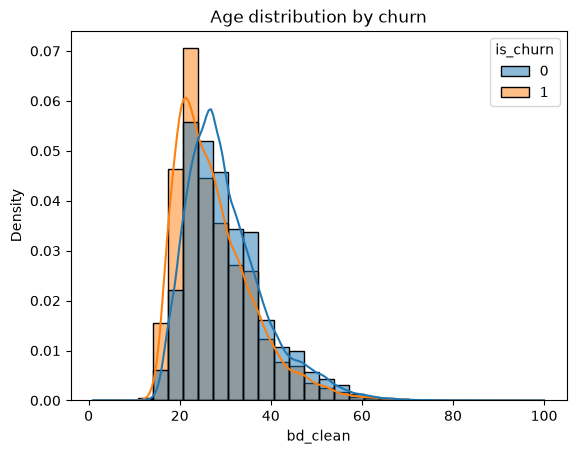

In [82]:
sns.histplot(
    data=eda,
    x='bd_clean',
    hue='is_churn',
    bins=30,
    kde=True,
    stat='density',
    common_norm=False
)

plt.title('Age distribution by churn')
plt.show()

In [83]:
eda["bd_missing"] = eda["bd_clean"].isna()

eda.groupby("bd_missing")["is_churn"].agg(
    ["count", "mean"]
)

,count,mean
bd_missing,,
False,389140,0.088436
True,603791,0.048124


In [84]:
eda.loc[eda["bd_clean"].notna(), "bd_clean"].quantile(
    [0, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 1]
)

0.00      1.0
0.01     17.0
0.05     19.0
0.25     24.0
0.50     28.0
0.75     34.0
0.95     48.0
0.99     57.0
1.00    100.0
Name: bd_clean, dtype: float64

In [85]:
eda["age_group"] = pd.cut(
    eda["bd_clean"],
    bins=[0, 18, 25, 35, 45, 55, 65, 100],
    labels=["<18", "18-25", "26-35", "36-45", "46-55", "56-65", "66+"],
    right=False
)

eda.groupby("age_group", observed=True)["is_churn"].agg(
    ["count", "mean"]
)

,count,mean
age_group,,
<18,9279,0.197758
18-25,104506,0.126931
26-35,179263,0.072625
36-45,67207,0.068430
46-55,22417,0.058839
56-65,5308,0.054069
66+,1154,0.077990


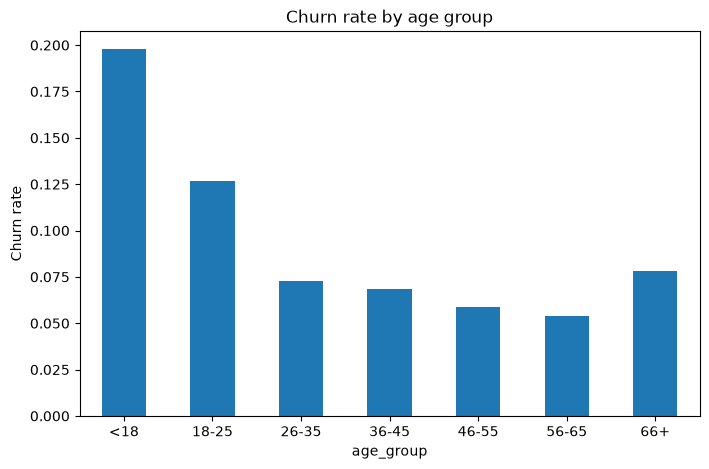

In [86]:
eda.groupby("age_group", observed=True)["is_churn"].mean().plot(
    kind="bar",
    figsize=(8, 5)
)
plt.ylabel("Churn rate")
plt.xticks(rotation=0)
plt.title("Churn rate by age group")
plt.show()

### 4. Registration Features

Explore whether registration timing and missing registration information are associated with churn.

#### 4.1. Registration channel

In [87]:
eda.groupby("registered_via")["is_churn"].agg(["count", "mean"]).sort_values("mean", ascending=False)

,count,mean
registered_via,,
4.0,49283,0.182558
3.0,105445,0.127090
9.0,236620,0.086362
13.0,3087,0.085196
7.0,482726,0.030160


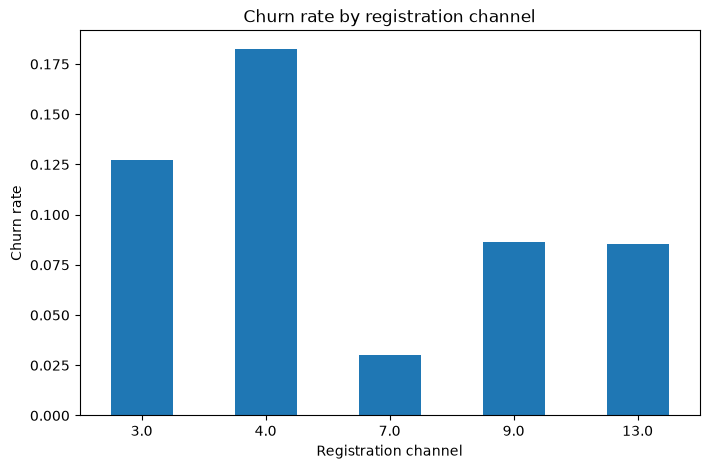

In [88]:
eda.groupby("registered_via")["is_churn"].mean().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.ylabel("Churn rate")
plt.xlabel("Registration channel")
plt.xticks(rotation=0)
plt.title("Churn rate by registration channel")
plt.show()

#### 4.2. Registration Year

In [89]:
eda["registration_date"] = pd.to_datetime(
    eda["registration_init_time"],
    format="%Y%m%d",
    errors="coerce"
)

In [90]:
eda["registration_date"].isna().sum()

np.int64(115770)

In [91]:
eda["registration_date"].min(), eda["registration_date"].max()

(Timestamp('2004-03-26 00:00:00'), Timestamp('2017-03-30 00:00:00'))

In [92]:
eda["registration_year"] = eda["registration_date"].dt.year

eda.groupby("registration_year")["is_churn"].agg(
    ["count", "mean"]
).sort_values("mean", ascending=False)

,count,mean
registration_year,,
2017.0,16691,0.116170
2014.0,91680,0.076036
2013.0,117059,0.073006
2009.0,15804,0.071881
2016.0,206892,0.069698
2008.0,17725,0.062736
2015.0,162008,0.062201
2012.0,77280,0.060520
2007.0,26355,0.058547


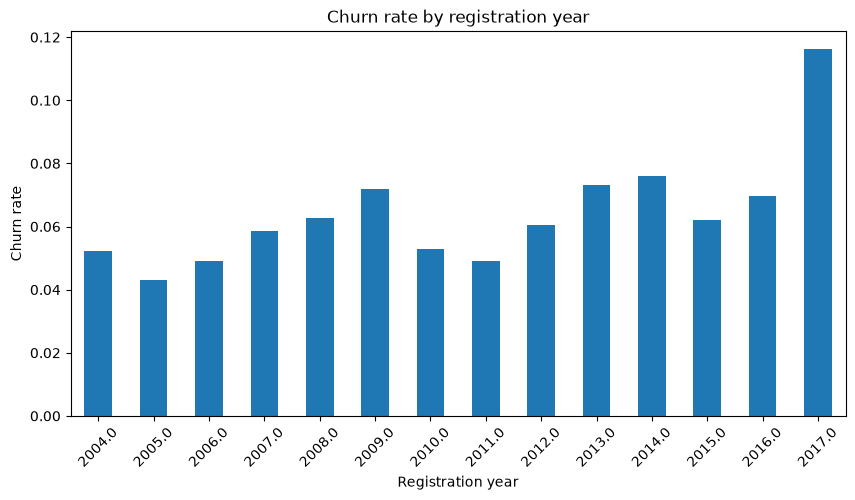

In [93]:
year_churn = (
    eda.groupby("registration_year")["is_churn"]
    .agg(["count", "mean"])
    .sort_index()
)

year_churn["mean"].plot(kind="bar", figsize=(10, 5))

plt.ylabel("Churn rate")
plt.xlabel("Registration year")
plt.title("Churn rate by registration year")
plt.xticks(rotation=45)
plt.show()

#### 4.3. Registration Month

In [94]:
eda["registration_month"] = eda["registration_date"].dt.month_name()

eda.groupby("registration_month")["is_churn"].agg(
    ["count", "mean"]
).sort_values("mean", ascending=False)

,count,mean
registration_month,,
February,72651,0.081568
January,93707,0.080133
March,67086,0.068464
December,84608,0.065467
April,51268,0.064426
June,60608,0.064001
September,70357,0.063746
November,81403,0.061017
August,78424,0.060925


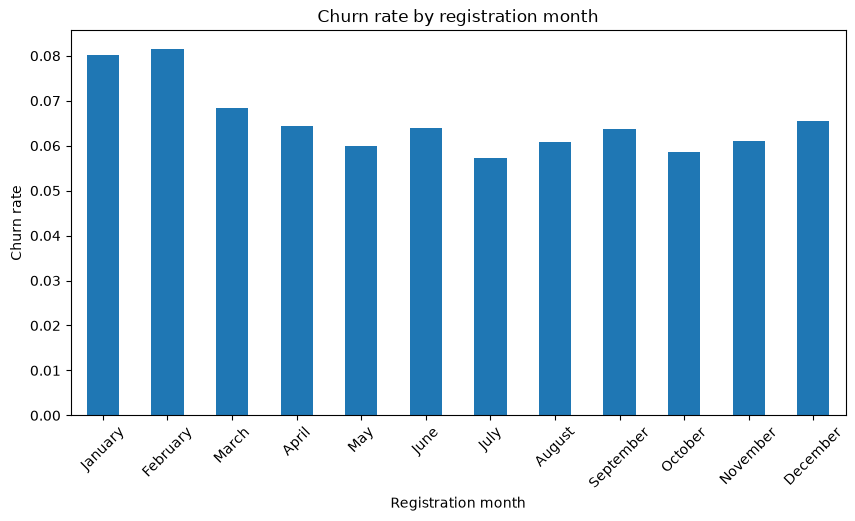

In [95]:
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

eda["registration_month"] = pd.Categorical(
    eda["registration_date"].dt.month_name(),
    categories=month_order,
    ordered=True
)

eda.groupby("registration_month")["is_churn"].mean().plot(
    kind="bar",
    figsize=(10, 5)
)

plt.ylabel("Churn rate")
plt.xlabel("Registration month")
plt.title("Churn rate by registration month")
plt.xticks(rotation=45)
plt.show()

#### 4.4. Missing Registration Information

In [96]:
eda["registration_info_missing"] = (
    eda["city"].isna()
    & eda["registered_via"].isna()
    & eda["registration_init_time"].isna()
)

eda.groupby("registration_info_missing")["is_churn"].agg(
    ["count", "mean"]
)

,count,mean
registration_info_missing,,
False,877161,0.065729
True,115770,0.050238


### 5. Transaction Features

These features describe payment behavior, subscription plans, discounts, renewals, cancellations, and transaction frequency.

#### 5.1. Transaction Filtering and Aggregation

In [8]:
importlib.reload(src.transactions_train)

<module 'src.transactions_train' from '/Volumes/Kingston/Alesia/vs_projects/kkbox_churn/src/transactions_train.py'>

In [13]:
transactions = pd.read_csv(DATA_INTERIM / "transactions.csv")

In [14]:
transactions_filter = src.transactions_train.filter_transactions_by_cutoff(transactions, cutoff_date="2017-01-31")

In [15]:
transactions_agg = src.transactions_train.aggregate_transactions(transactions_filter)

In [16]:
transactions_agg.columns

Index(['msno', 'payment_method_most_frequent', 'plan_days_mean',
       'plan_list_price_median', 'actual_amount_paid_median',
       'discount_amount_mean', 'is_discount_rate', 'auto_renew_rate',
       'first_transaction', 'last_transaction', 'total_transactions',
       'is_cancel_rate', 'transaction_history_days'],
      dtype='str')

In [12]:
eda = eda.merge(transactions_agg, on='msno', how="left")

eda.head()

,msno,is_churn,city,bd,gender,registered_via,registration_init_time,payment_method_most_frequent,plan_days_mean,plan_list_price_median,actual_amount_paid_median,discount_amount_mean,is_discount_rate,auto_renew_rate,first_transaction,last_transaction,total_transactions,is_cancel_rate,transaction_history_days
0,waLDQMmcOu2jLDaV1ddDkgCrB/jl6sD66Xzs0Vqax1Y=,1,18.0,36.0,female,9.0,20050406.0,38.0,18.500000,74.5,74.5,0.000000,0.0,0.000000,2016-10-31,2017-01-07,2.0,0.000000,68.0
1,QA7uiXy8vIbUSPOkCf9RwQ3FsT8jVq2OxDr8zqa7bRQ=,1,10.0,38.0,male,9.0,20050407.0,39.0,28.772727,149.0,149.0,-6.772727,0.0,0.954545,2015-01-31,2017-01-31,22.0,0.045455,731.0
2,fGwBva6hikQmTJzrbz/2Ezjm5Cth5jZUNvXigKK2AFA=,1,11.0,27.0,female,9.0,20051016.0,39.0,30.000000,149.0,149.0,0.000000,0.0,0.800000,2016-02-02,2017-01-12,10.0,0.100000,345.0
3,mT5V8rEpa+8wuqi6x0DoVd3H5icMKkE9Prt49UlmK+4=,1,13.0,23.0,female,9.0,20051102.0,17.0,410.000000,894.0,894.0,0.000000,0.0,0.000000,2016-01-04,2016-01-06,2.0,0.000000,2.0
4,XaPhtGLk/5UvvOYHcONTwsnH97P4eGECeq+BARGItRw=,1,3.0,27.0,male,9.0,20051228.0,38.0,98.125000,149.0,149.0,0.000000,0.0,0.000000,2015-01-02,2017-01-28,8.0,0.000000,757.0


In [14]:
eda.isna().sum()

msno                                 0
is_churn                             0
city                            115770
bd                              115770
gender                          601239
registered_via                  115770
registration_init_time          115770
payment_method_most_frequent      2095
plan_days_mean                    2095
plan_list_price_median            2095
actual_amount_paid_median         2095
discount_amount_mean              2095
is_discount_rate                  2095
auto_renew_rate                   2095
first_transaction                 2095
last_transaction                  2095
total_transactions                2095
is_cancel_rate                    2095
transaction_history_days          2095
dtype: int64

### 6. Candidate Transaction Features

#### 6.1. Payment Method

In [104]:
eda.groupby("payment_method_most_frequent")["is_churn"].agg(["count", "mean"]).sort_values("mean", ascending=False).head(20)

,count,mean
payment_method_most_frequent,,
6.0,12,0.750000
15.0,95,0.631579
3.0,10,0.600000
22.0,1130,0.500885
5.0,6,0.500000
17.0,71,0.492958
13.0,365,0.482192
32.0,7868,0.473183
12.0,280,0.460714


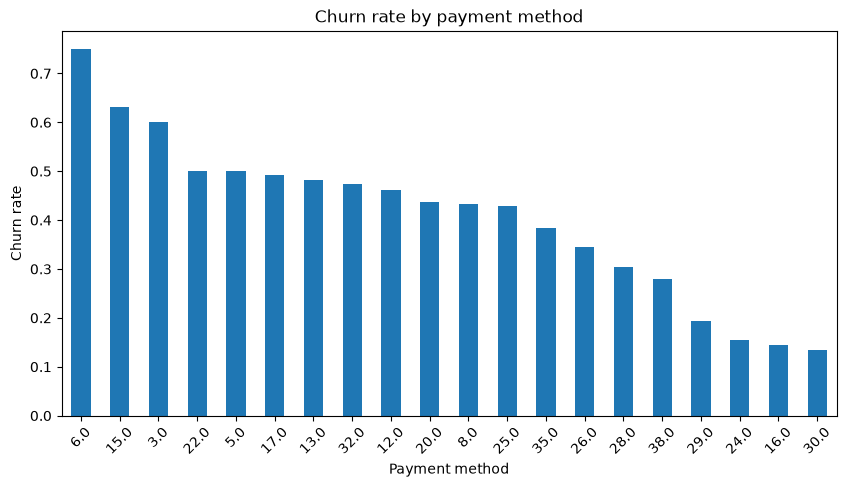

In [105]:
pay_method_churn = (
    eda.groupby("payment_method_most_frequent")["is_churn"]
    .agg(["count", "mean"])
    .sort_index().sort_values("mean", ascending=False).head(20)
)

pay_method_churn["mean"].plot(kind="bar", figsize=(10, 5))

plt.ylabel("Churn rate")
plt.xlabel("Payment method")
plt.title("Churn rate by payment method")
plt.xticks(rotation=45)
plt.show()

#### 6.2. Number of days in the plan

In [106]:
bins_2 = [0, 30, 90, 180, 365, np.inf]
labels_2 = ['0-30', '31-90', '91-180', '181-365', '365+']

eda["avg_plan_days_group"] = pd.cut(
    eda["plan_days_mean"], bins=bins_2, labels=labels_2, include_lowest=True
)

eda.groupby("avg_plan_days_group")["is_churn"].agg(["count", "mean"])

,count,mean
avg_plan_days_group,,
0-30,915182,0.051041
31-90,55629,0.134840
91-180,9751,0.346118
181-365,5032,0.450715
365+,5242,0.563525


#### 6.3. Auto renew and cancel rate

In [107]:
conditions = [
    eda["auto_renew_rate"] == 0,
    (eda["auto_renew_rate"] > 0) & (eda["auto_renew_rate"] < 1),
    eda["auto_renew_rate"] == 1
]
choices = ["0", ">0 and <1", "1"]
eda["renew_rate_group"] = np.select(conditions, choices, default=None)

eda.groupby("renew_rate_group")["is_churn"].agg(["count", "mean"])

,count,mean
renew_rate_group,,
0,99150,0.317418
1,810369,0.028756
>0 and <1,81317,0.098811


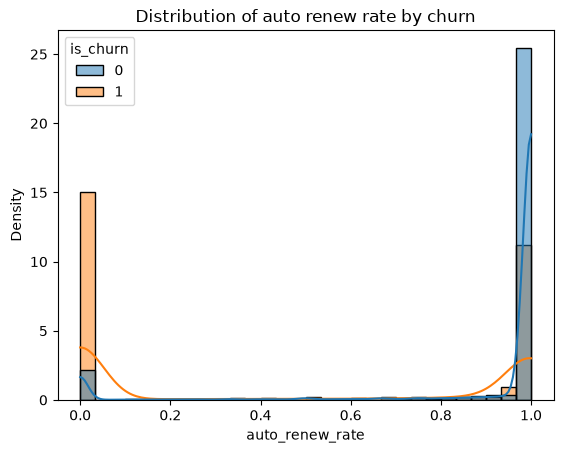

In [108]:
sns.histplot(
    data=eda,
    x='auto_renew_rate',
    hue='is_churn',
    bins=30,
    kde=True,
    stat='density',
    common_norm=False
)

plt.title('Distribution of auto renew rate by churn')
plt.show()

In [109]:
conditions= [
    eda["is_cancel_rate"] == 0,
    (eda["is_cancel_rate"] > 0) & (eda["is_cancel_rate"] < 1),
    eda["is_cancel_rate"] == 1
]
choices = ["0", ">0 and <1", "1"]
eda["cancel_rate_group"] = np.select(conditions, choices, default=None)

eda.groupby("cancel_rate_group")["is_churn"].agg(["count", "mean"])

,count,mean
cancel_rate_group,,
0,790149,0.059572
1,4,0.500000
>0 and <1,200683,0.078417


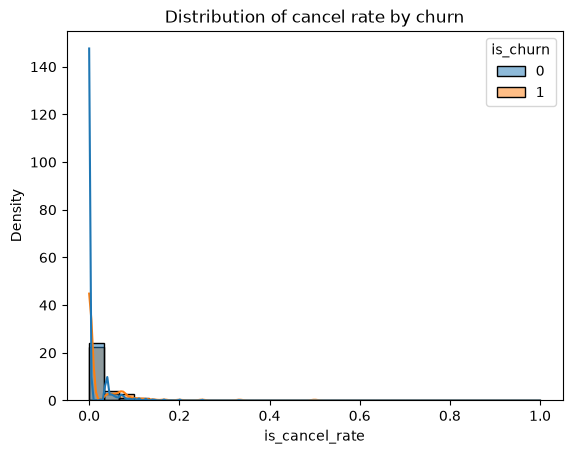

In [110]:
sns.histplot(
    data=eda,
    x='is_cancel_rate',
    hue='is_churn',
    bins=30,
    kde=True,
    stat='density',
    common_norm=False
)

plt.title('Distribution of cancel rate by churn')
plt.show()

#### 6.4. Amount of transactions

In [111]:
eda['total_transactions'].max()

np.float64(244.0)

In [112]:
(eda["total_transactions"] == 0).sum()

np.int64(0)

In [113]:
bins = [0, 1, 5, 10, 20, 40, 80, np.inf]
labels = ["1", "2-5", "6-10", "11-20", "21-40", "41-80", "81+"]

eda["transaction_count_group"] = pd.cut(
    eda["total_transactions"], bins=bins, labels=labels, include_lowest=True
)

eda.groupby("transaction_count_group")["is_churn"].agg(["count", "mean"])

,count,mean
transaction_count_group,,
1,35098,0.253832
2-5,121256,0.125066
6-10,160145,0.059864
11-20,356901,0.051723
21-40,316360,0.033373
41-80,1067,0.114339
81+,9,1.000000


In [114]:
eda[eda["total_transactions"] < 20].groupby("total_transactions")["is_churn"].agg(["count", "mean"])

,count,mean
total_transactions,,
1.0,35098,0.253832
2.0,35385,0.153087
3.0,30963,0.128508
4.0,29782,0.112585
5.0,25126,0.096155
6.0,33398,0.070603
7.0,38488,0.052380
8.0,41894,0.054137
9.0,26735,0.058463


In [118]:
eda["discount_group"] = pd.qcut(
    eda["discount_amount_mean"],
    q=5,
    duplicates="drop"
)

eda.groupby("discount_group", observed=True)["is_churn"].agg(
    ["count", "mean"]
)

,count,mean
discount_group,,
"(-1788.001, -5.96]",220445,0.040341
"(-5.96, 0.0]",703433,0.070547
"(0.0, 177.667]",66958,0.064100


#### 6.5. Discounts

In [30]:
conditions= [
    eda["discount_amount_mean"] < 0,
    eda["discount_amount_mean"] == 0,
    eda["discount_amount_mean"] > 0
]
choices = ["<0", "0", ">0"]
eda["discount_group"] = np.select(conditions, choices, default=None)

eda.groupby("discount_group")["is_churn"].agg(["count", "mean"])

,count,mean
discount_group,,
0,642918,0.073639
<0,280960,0.039771
>0,66958,0.064100


In [32]:
eda["discount_group"].value_counts(normalize=True)*100

discount_group
0     64.886419
<0    28.355853
>0     6.757728
Name: proportion, dtype: float64

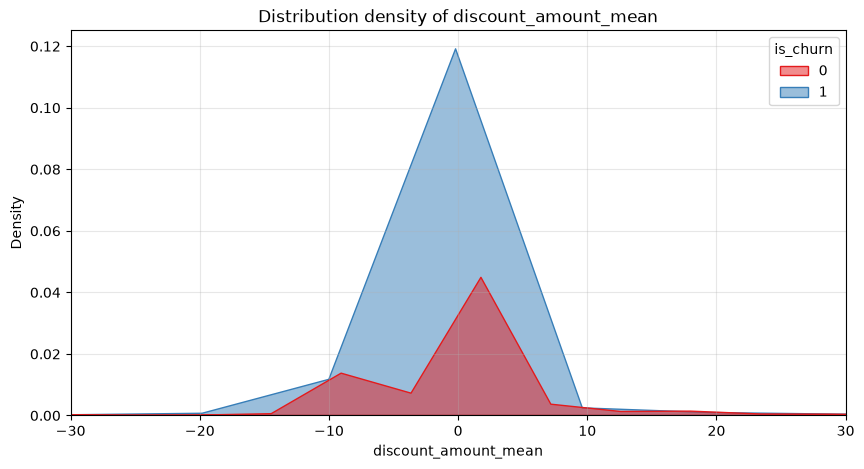

In [33]:
plt.figure(figsize=(10, 5))

sns.kdeplot(
    data=eda, 
    x='discount_amount_mean', 
    hue='is_churn', 
    fill=True, 
    common_norm=False,
    palette='Set1',
    alpha=0.5
)

plt.xlim(-30, 30) 

plt.title('Distribution density of discount_amount_mean')
plt.xlabel('discount_amount_mean')
plt.ylabel('Density')
plt.grid(True, alpha=0.3)
plt.show()


#### 6.6. Transaction history

In [116]:
bins_history = [0, 30, 90, 180, 365, 730, np.inf]
labels_history = ['0-30 days', '1-3 months', '3-6 months', '6-12 months', '1-2 years', '2+ years']

eda["history_group"] = pd.cut(
    eda["transaction_history_days"], 
    bins=bins_history, 
    labels=labels_history, 
    include_lowest=True
)

history_churn_analysis = eda.groupby("history_group", observed=False)["is_churn"].agg(["count", "mean"])
print(history_churn_analysis)

                count      mean
history_group                  
0-30 days       50494  0.209748
1-3 months      43805  0.094601
3-6 months      72955  0.061024
6-12 months    180202  0.068867
1-2 years      402867  0.059595
2+ years       240513  0.029953


### 7. User Listening Behavior Analysis

In [8]:
importlib.reload(src.logs_train)
user_logs_agg = src.logs_train.extract_raw_log_aggregates(train["msno"], cutoff_date="2017-01-31")

In [9]:
user_logs_agg.columns

Index(['msno', 'total_num_25', 'total_num_50', 'total_num_75', 'total_num_985',
       'total_num_100', 'total_num_unq', 'total_secs', 'last_activity',
       'active_days'],
      dtype='str')

In [10]:
user_logs_agg["msno"].nunique(), len(user_logs_agg)

(823110, 823110)

In [11]:
user_logs_agg["last_activity"].max()

Timestamp('2017-01-31 00:00:00')

In [39]:
user_logs_agg[
    ["total_secs", "active_days"]
].describe()

,total_secs,active_days
count,3.178364e+06,3178364.0
mean,4.201685e+05,51.786464
std,9.873947e+05,81.41571
min,0.000000e+00,1.0
25%,1.985954e+03,2.0
50%,2.073453e+04,5.0
75%,3.810554e+05,70.0
max,2.774147e+07,342.0


In [40]:
eda = eda.merge(
    user_logs_agg,
    on="msno", 
    how="left"
)

#### 7.1. Active days

In [41]:
eda.groupby("is_churn")[
    ["active_days"]
].agg(["mean", "median"])

active_days       
                mean median
is_churn                   
0         125.353668  109.0
1         107.569884   87.0

In [42]:
eda["active_days"].max()

np.int64(342)

In [43]:
eda["active_days_group"] = pd.cut(
    eda["active_days"],
    bins=[0, 14, 30, 90, 180, 365],
    labels=['0-14 days', '15-30 days', '1-3 months', '3-6 months', '6-12 months']
)

eda.groupby("active_days_group")["is_churn"].agg(["count", "mean"])

,count,mean
active_days_group,,
0-14 days,79690,0.082394
15-30 days,88502,0.078608
1-3 months,211092,0.070367
3-6 months,209763,0.064806
6-12 months,234063,0.049452


#### 7.2. Number of seconds

In [44]:
eda.groupby("is_churn")[
    ["total_secs"]
].agg(["mean", "median"])

total_secs             
                  mean       median
is_churn                           
0         1.013796e+06  563801.0865
1         8.882802e+05  464238.7915

In [45]:
eda["total_secs_group"] = pd.qcut(
    eda["total_secs"],
    q=5,
    duplicates="drop"
)

eda.groupby("total_secs_group")["is_churn"].agg(
    ["count", "mean"]
)

,count,mean
total_secs_group,,
"(0.077, 121566.787]",164622,0.074553
"(121566.787, 373062.884]",164622,0.070471
"(373062.884, 795836.94]",164622,0.064924
"(795836.94, 1583185.948]",164622,0.061067
"(1583185.948, 27741473.455]",164622,0.054252


In [46]:
eda["total_secs"].value_counts().head(10)


total_secs
215.000    6
1.071      5
265.000    5
215.144    5
265.561    5
285.000    4
1.097      4
265.508    4
242.000    4
235.000    4
Name: count, dtype: int64

In [47]:
eda["total_secs"].nunique()

822743

In [48]:
eda.groupby("is_churn")[
    ['total_num_25', 'total_num_50', 'total_num_75','total_num_985', 'total_num_100']
].agg(["mean", "median"])

total_num_25        total_num_50        total_num_75         \
                 mean median         mean median         mean median   
is_churn                                                               
0          816.511561  411.0   202.676471  111.0   126.905133   72.0   
1          739.733668  357.0   187.998711   98.0   115.806634   63.0   

         total_num_985        total_num_100          
                  mean median          mean  median  
is_churn                                             
0           140.734976   73.0   3841.038884  2062.0  
1           128.456916   63.0   3355.185075  1693.0

In [49]:
eda["total_num_100_group"] = pd.qcut(
    eda["total_num_100"],
    q=5,
    duplicates="drop"
)

eda.groupby("total_num_100_group", observed=True)["is_churn"].agg(
    ["count", "mean"]
)

,count,mean
total_num_100_group,,
"(-0.001, 427.0]",164670,0.074373
"(427.0, 1351.0]",164618,0.070940
"(1351.0, 2932.0]",164635,0.064780
"(2932.0, 5907.0]",164593,0.061041
"(5907.0, 195459.0]",164594,0.054127


### Final conclusions

- Churn is a relatively rare event in this dataset, so the problem is strongly imbalanced and accuracy alone is not a reliable evaluation metric. 

- Demographic features provide some signal, but the strongest predictors are behavioral and transactional: lower engagement, weaker renewal patterns, and less active subscription history are associated with higher churn risk. 

- Therefore, the final model should prioritize behavioral features, handle missing or invalid values carefully, and be evaluated using imbalance-aware metrics such as recall and PR-AUC.